In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
weights = np.random.rand(2)
bias = np.random.rand()
lr = 0.1
def sigmoid(z):
  return 1 / (1 + np.exp(-z))

In [3]:
X = np.array([[0,0],
              [0,1],
              [1,0],
              [1,1]])
y = np.array([0,0,0,1])


In [5]:
def train_model(X, y, weights, bias, lr, num_epochs):
  w_train = weights.copy()
  b_train = bias
  errors = []
  for epoch in range(num_epochs):
    total_error = 0
    for i in range(len(X)):
      z = np.dot(X[i], w_train) + b_train
      y_pred = sigmoid(z)
      error = y[i] - y_pred
      total_error += error**2
      w_train += lr * error * X[i]
      b_train += lr * error
    errors.append(total_error)
  return errors

In [6]:
limits = [50, 100, 500, 1000]
colors = ['crimson', 'orange', 'royalblue', 'seagreen']

In [7]:
plt.figure(figsize=(12, 10))
for i, limit in enumerate(limits):
  errors = train_model(X, y, weights, bias, lr, limit)
  min_err = min(errors)
  print(f"Limit: {limit:4} epochs | Minimum Error: {min_err:.6f}")

Limit:   50 epochs | Minimum Error: 0.437055
Limit:  100 epochs | Minimum Error: 0.256635
Limit:  500 epochs | Minimum Error: 0.032487
Limit: 1000 epochs | Minimum Error: 0.009496


<Figure size 1200x1000 with 0 Axes>

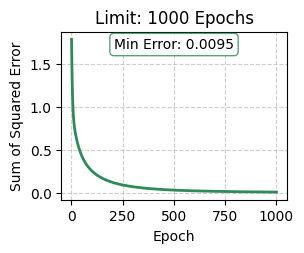

In [14]:
plt.subplot(2, 2, i + 1)
plt.plot(range(1, limit + 1), errors, color=colors[i], linewidth=2)
plt.title(f"Limit: {limit} Epochs")
plt.annotate(f'Min Error: {min_err:.4f}'
    , xy=(0.5, 0.9), xycoords='axes fraction',
      ha='center', fontsize=10,
      bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=colors[i], alpha=0.8))
plt.xlabel("Epoch")
plt.ylabel("Sum of Squared Error")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()